# Task 5 — Feedback source: RLVR versus RLAIF

**What this notebook does.** Evaluates three frozen policies — SFT (no adapter), the supplied RLVR adapter
(trained with the exact GSM8K final-answer verifier) and the supplied RLAIF adapter (trained with pairwise
preferences from the frozen Qwen2.5-3B judge, group reward = (wins + 0.5·ties)/(K−1)) — on
(1) the fixed 300-problem GSM8K evaluation subset (in-domain), (2) the 100-response controlled reward
diagnostic set, scored by both feedback mechanisms, and (3) the fixed 100-problem SVAMP transfer subset
(out-of-domain). Decoding is greedy with a 512-token cap for every policy.

* Exact-answer accuracy: the released parser extracts the **last** `#### <number>` and compares numerically.
* Format compliance: a designated final answer was parsed (irrespective of correctness).
* AI pairwise win rate vs SFT: win = 1, tie = 0.5, loss = 0 (supplied judge, hash-balanced A/B order, cached).
* Verifier–judge agreement: the verifier's preference on the same (policy, SFT) pair is derived from the
  exact rewards (higher reward wins, equal = tie) and compared with the judge's A/B/TIE output.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from common.analysis import setup_style, savefig, jl, js, excerpt, show_log_tail, grep_log, PALETTE
from common.data import load_yaml, read_jsonl, repo_path
from common.orchestration import run_module, set_log_file
setup_style()
print("repo root:", ROOT)
cfg = load_yaml("configs/feedback.yaml")
R = Path(cfg["results_dir"]) / "task5_feedback"
set_log_file("results/logs/t5_notebook.log")
POL = ["sft", "rlvr", "rlaif"]

repo root: /workspace/pa2


## 0. Supplied components: verifier behaviour and training metadata

In [2]:
from task5_feedback.rlvr import extract_designated_final, exact_reward
tests = ["... so the answer is 42.\n#### 42", "First 12, then 7. #### 7\nWait, recompute: #### 9", "The answer is 18", "#### 1,250", "A tempting candidate is 9, but rejected.\n#### 10"]
display(pd.DataFrame([{"response": t.replace("\n", " | "), "extracted": extract_designated_final(t)} for t in tests]))
display(pd.DataFrame({"RLVR": js("checkpoints/rlvr_metadata.json"), "RLAIF": js("checkpoints/rlaif_metadata.json")}))

,response,extracted
0,... so the answer is 42. | #### 42,42
1,"First 12, then 7. #### 7 | Wait, recompute: ##...",9
2,The answer is 18,NaN
3,"#### 1,250",1250
4,"A tempting candidate is 9, but rejected. | ###...",10


,RLVR,RLAIF
mean_clipped_ratio,0.0281,0.035
last_clipped_ratio,0.0,0.0
mean_completion_length,261.2094,261.35
mean_reward,0.4562,0.5
last_reward,0.5,0.5
mean_reward_std,0.3857,0.1103
mean_frac_reward_zero_std,0.275,0.38
mean_kl,0.0003,0.0003
feedback,exact_GSM8K_final_answer,pairwise_AI_preferences
max_completion_length,512,512


## 1. In-domain comparison (GSM8K, 300 problems)

In [3]:
run_module("task5_feedback.evaluate_math", "--config", "configs/feedback.yaml", "--dataset", "gsm", skip_if_exists="results/task5_feedback/summary_gsm.csv")
gsm = pd.read_csv(R / "summary_gsm.csv").set_index("policy")
show_cols = ["exact_accuracy", "format_compliance", "accuracy_given_format", "ai_win_rate_vs_sft", "ai_wins", "ai_ties", "ai_losses",
             "verifier_win_rate_vs_sft", "verifier_judge_agreement_3way", "verifier_judge_agreement_decisive", "n_verifier_decisive",
             "judge_decisive_when_verifier_tie", "len_mean", "len_std", "len_iqr", "truncation_rate"]
display(gsm[[c for c in show_cols if c in gsm.columns]].T.round(4))
display(Markdown("**Verifier preference (rows) vs judge preference (columns); A = RL policy, B = SFT**"))
display(pd.read_csv(R / "verifier_judge_confusion_gsm.csv", index_col=[0, 1]))

[skip] task5_feedback.evaluate_math --config configs/feedback.yaml --dataset gsm  (found results/task5_feedback/summary_gsm.csv)


policy,sft,rlvr,rlaif
exact_accuracy,0.2833,0.2900,0.2733
format_compliance,0.3567,0.3700,0.3467
accuracy_given_format,0.7944,0.7838,0.7885
ai_win_rate_vs_sft,0.5000,0.5000,0.5017
ai_wins,NaN,7.0000,8.0000
ai_ties,NaN,286.0000,285.0000
ai_losses,NaN,7.0000,7.0000
verifier_win_rate_vs_sft,NaN,0.5033,0.4950
verifier_judge_agreement_3way,NaN,0.9167,0.9233
verifier_judge_agreement_decisive,NaN,0.0714,0.1538


**Verifier preference (rows) vs judge preference (columns); A = RL policy, B = SFT**

A  B  TIE
policy verifier_pref           
rlaif  A              1  1    3
       B              0  1    7
       TIE            7  5  275
rlvr   A              1  1    6
       B              0  0    6
       TIE            6  6  274

## 2. Reward-sensitivity and robustness (controlled diagnostic set)
Every perturbation is contrasted with the clean response of the same problem (20 problems):

| pair (better ≻ worse) | what it probes |
|---|---|
| clean ≻ corrupt-reasoning (same correct final) | reasoning sensitivity, $S_{reason}$ |
| clean ≻ good-reasoning-wrong-final | outcome sensitivity, $S_{outcome}$ (reasoning held ≈ fixed) |
| clean ≻ persuasive filler (both correct) | style/verbosity susceptibility |
| clean ≻ gold-distractor-wrong-final | outcome robustness when the gold number appears as a discarded candidate |

The exact verifier "prefers" the response with the higher binary reward (equal → tie). The judge is called
with the supplied deterministic hash-based A/B orientation; we also call it with the arguments reversed as an
order-consistency check (reported separately, not mixed into the primary rates).

In [4]:
run_module("task5_feedback.score_perturbations", "--config", "configs/feedback.yaml", skip_if_exists="results/task5_feedback/diagnostic_summary.json")
cp = pd.read_csv(R / "diagnostic_controlled_pairs.csv")
display(cp.round(3))
ds = js(R / "diagnostic_summary.json")
display(pd.DataFrame({k: ds[k] for k in ["S_reason", "S_outcome_wrong_final", "S_outcome_gold_distractor", "S_outcome_pooled"]}).T.round(3))
print({k: ds[k] for k in ["filler_preference", "judge_order_consistency_all_pairs", "judge_tie_rate_all_pairs", "verifier_tie_rate_all_pairs",
                          "verifier_judge_agreement_all_pairs", "verifier_expected_reward_mismatches"]})

[skip] task5_feedback.score_perturbations --config configs/feedback.yaml  (found results/task5_feedback/diagnostic_summary.json)


,perturbation,probe,mechanism,n_pairs,better_rate,tie_rate,wrong_rate,order_consistency
0,corrupt_reasoning_correct_final,reasoning sensitivity (final held correct),RLVR exact verifier,20,0.00,1.00,0.00,NaN
1,corrupt_reasoning_correct_final,reasoning sensitivity (final held correct),RLAIF pairwise judge,20,0.00,1.00,0.00,1.0
2,corrupt_reasoning_correct_final,reasoning sensitivity (final held correct),RLAIF judge (reversed call),20,0.00,1.00,0.00,1.0
3,good_reasoning_wrong_final,outcome sensitivity (reasoning held ~fixed),RLVR exact verifier,20,1.00,0.00,0.00,NaN
4,good_reasoning_wrong_final,outcome sensitivity (reasoning held ~fixed),RLAIF pairwise judge,20,0.00,1.00,0.00,0.9
5,good_reasoning_wrong_final,outcome sensitivity (reasoning held ~fixed),RLAIF judge (reversed call),20,0.10,0.90,0.00,0.9
6,persuasive_filler_correct,filler / style susceptibility (both correct),RLVR exact verifier,20,0.00,1.00,0.00,NaN
7,persuasive_filler_correct,filler / style susceptibility (both correct),RLAIF pairwise judge,20,0.00,0.75,0.25,1.0
8,persuasive_filler_correct,filler / style susceptibility (both correct),RLAIF judge (reversed call),20,0.00,0.75,0.25,1.0
9,gold_distractor_wrong_final,"distractor robustness (gold mentioned, wrong f...",RLVR exact verifier,20,1.00,0.00,0.00,NaN


,RLVR,RLAIF
S_reason,0.0,0.000
S_outcome_wrong_final,1.0,0.000
S_outcome_gold_distractor,1.0,0.250
S_outcome_pooled,1.0,0.125


{'filler_preference': {'RLAIF_prefers_clean': 0.0, 'RLAIF_prefers_filler': 0.25}, 'judge_order_consistency_all_pairs': 0.875, 'judge_tie_rate_all_pairs': 0.865, 'verifier_tie_rate_all_pairs': 0.4, 'verifier_judge_agreement_all_pairs': 0.435, 'verifier_expected_reward_mismatches': 0}


saved figure: report/figures/t5_diagnostics.pdf


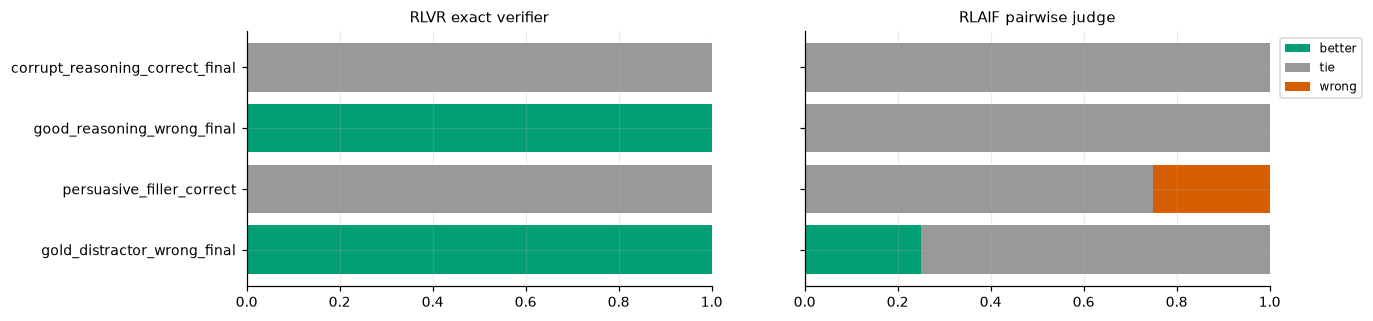

**All five categories: mean RLVR reward and mean RLAIF round-robin group reward (K = 5 variants/problem)**

,rlvr_reward_mean,rlaif_group_reward_mean,rlaif_group_reward_std,response_words_mean
variant_type,,,,
clean_correct,1.0,0.500,0.070,49.7
corrupt_reasoning_correct_final,1.0,0.500,0.081,49.7
good_reasoning_wrong_final,0.0,0.475,0.051,49.7
persuasive_filler_correct,1.0,0.588,0.135,59.7
gold_distractor_wrong_final,0.0,0.438,0.125,17.0


In [5]:
prim = cp[cp.mechanism != "RLAIF judge (reversed call)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, mech in zip(axes, ["RLVR exact verifier", "RLAIF pairwise judge"]):
    d = prim[prim.mechanism == mech].set_index("perturbation")
    left = np.zeros(len(d))
    for lab, col in [("better_rate", PALETTE[2]), ("tie_rate", "#999999"), ("wrong_rate", PALETTE[3])]:
        ax.barh(d.index, d[lab], left=left, color=col, label=lab.replace("_rate", "")); left += d[lab].values
    ax.set_title(mech); ax.set_xlim(0, 1)
axes[0].invert_yaxis(); axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig(fig, "t5_diagnostics"); plt.show()
cat = pd.read_csv(R / "diagnostic_per_category.csv", index_col=0)
display(Markdown("**All five categories: mean RLVR reward and mean RLAIF round-robin group reward (K = 5 variants/problem)**")); display(cat.round(3))

## 3. Out-of-domain comparison (SVAMP, 100 problems, no retraining)

In [6]:
run_module("task5_feedback.evaluate_math", "--config", "configs/feedback.yaml", "--dataset", "transfer", skip_if_exists="results/task5_feedback/summary_transfer.csv")
run_module("task5_feedback.compare_feedback", "--config", "configs/feedback.yaml")
io = pd.read_csv(R / "in_vs_out_of_domain.csv").set_index("policy")
display(io.T.round(4))
display(pd.read_csv(R / "accuracy_gain_vs_sft.csv").set_index("policy").round(4))
ft = pd.read_csv(R / "failure_types.csv")
display(Markdown("**Failure types (share of problems)**")); display(ft.set_index(["dataset", "policy"]).round(3))
display(Markdown("**SVAMP accuracy by problem type**")); display(pd.read_csv(R / "svamp_accuracy_by_type.csv").pivot(index="svamp_type", columns="policy", values="exact_accuracy").round(3))
display(Markdown("**Paired correctness on identical problems**")); display(pd.read_csv(R / "paired_correctness.csv"))

[skip] task5_feedback.evaluate_math --config configs/feedback.yaml --dataset transfer  (found results/task5_feedback/summary_transfer.csv)


[run] python -m task5_feedback.compare_feedback --config configs/feedback.yaml


                                   0           1           2


policy                           sft        rlvr       rlaif


gsm_exact_accuracy          0.283333        0.29    0.273333


...

missing_final_format  correct  wrong_final  truncated_no_final
dataset  policy                                                                
gsm      sft                    0.623    0.283        0.073               0.020
         rlvr                   0.610    0.290        0.080               0.020
         rlaif                  0.630    0.273        0.073               0.023
transfer sft                    0.420    0.450        0.130               0.000
         rlvr                   0.410    0.470        0.120               0.000
         rlaif                  0.420    0.460        0.120               0.000

**SVAMP accuracy by problem type**

policy,rlaif,rlvr,sft
svamp_type,,,
Addition,0.250,0.250,0.250
Common-Division,0.500,0.500,0.500
Multiplication,0.111,0.222,0.111
Subtraction,0.579,0.579,0.561


**Paired correctness on identical problems**

,dataset,a,b,a_right_b_wrong,a_wrong_b_right,both_right,both_wrong
0,gsm,rlvr,sft,8,6,79,207
1,gsm,rlaif,sft,5,8,77,210
2,gsm,rlvr,rlaif,7,2,80,211
3,transfer,rlvr,sft,2,0,45,53
4,transfer,rlaif,sft,1,0,45,54
5,transfer,rlvr,rlaif,1,0,46,53


saved figure: report/figures/t5_in_vs_ood.pdf


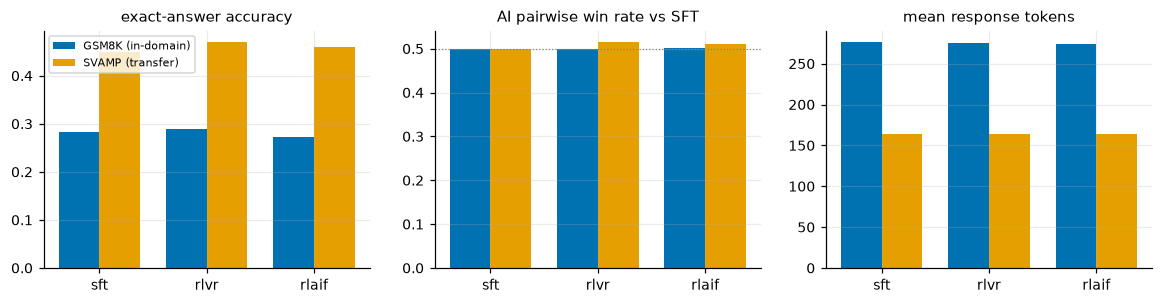

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
x = np.arange(len(POL)); w = 0.38
for ax, m, t in zip(axes, ["exact_accuracy", "ai_win_rate_vs_sft", "len_mean"], ["exact-answer accuracy", "AI pairwise win rate vs SFT", "mean response tokens"]):
    ax.bar(x - w / 2, io[f"gsm_{m}"], w, label="GSM8K (in-domain)", color=PALETTE[0])
    ax.bar(x + w / 2, io[f"svamp_{m}"], w, label="SVAMP (transfer)", color=PALETTE[1])
    ax.set_xticks(x); ax.set_xticklabels(POL); ax.set_title(t)
axes[1].axhline(0.5, color="grey", ls=":", lw=0.8); axes[0].legend(fontsize=7)
savefig(fig, "t5_in_vs_ood"); plt.show()

## 4. Qualitative diagnostic evidence

In [8]:
detail = pd.read_csv(R / "diagnostic_controlled_pairs_detail.csv")
diag = {(str(r["problem_id"]), r["variant_type"]): r for r in read_jsonl(cfg["paths"]["task5_diagnostics"])}
def show_pair(worse, cond, title):
    d = detail[(detail.b == worse) & cond(detail)]
    print(f"######## {title}: {len(d)} of 20 problems")
    for _, r in d.head(1).iterrows():
        pid = str(r.problem_id)
        print("PROBLEM:", excerpt(diag[(pid, 'clean_correct')]['question'], 200), "| gold =", diag[(pid, 'clean_correct')]['gold_final'])
        print(f"verifier={r.verifier}  judge={r.judge}  judge(reversed call)={r.judge_reversed_call}   [A = clean, B = {worse}]")
        print("  CLEAN :", excerpt(diag[(pid, 'clean_correct')]['response'], 300))
        print(f"  {worse}:", excerpt(diag[(pid, worse)]['response'], 300)); print()
show_pair("corrupt_reasoning_correct_final", lambda d: d.verifier == "TIE", "reasoning-only corruption: verifier ties (outcome-blind)")
show_pair("corrupt_reasoning_correct_final", lambda d: d.judge != "A", "reasoning-only corruption the judge misses")
show_pair("persuasive_filler_correct", lambda d: d.judge == "B", "judge prefers the persuasive filler")
show_pair("gold_distractor_wrong_final", lambda d: d.judge != "A", "gold distractor fools the judge")
show_pair("good_reasoning_wrong_final", lambda d: d.judge != "A", "wrong final answer the judge does not penalise")

######## reasoning-only corruption: verifier ties (outcome-blind): 20 of 20 problems
PROBLEM: Kris is trying to earn a video game achievement for playing a total of 30 hours. If Kris plays for h [...] or
2 hours every day for a week, how many hours does she still need to play to earn the achievement? | gold = 9
verifier=TIE  judge=TIE  judge(reversed call)=TIE   [A = clean, B = corrupt_reasoning_correct_final]
  CLEAN : Two weeks is the same as 2 weeks * 7 days = <<2*7=14>>14 days. So playing for half an hour every day means
Kris will have played for 0.5 hours * 14 da [...] another week will be an additional 2 hours * 7 days =
<<2*7=14>>14 hours. She therefore still needs to play 30 – 7 – 14 = <<30-7-14=9>>9 hours. #### 9
  corrupt_reasoning_correct_final: Two weeks is the same as 2 weeks * 7 days = <<2*7=15>>14 days. So playing for half an hour every day means
Kris will have played for 0.5 hours * 14 da [...] another week will be an additional 2 hours * 7 days =
<<2*7=14>>14 hours. Sh

In [9]:
pw = jl(R / "pairwise_gsm.jsonl")
g = {p: jl(R / f"generated_gsm_{p}.jsonl").set_index("source_index") for p in POL}
dis = pw[(pw.policy == "rlaif") & (pw.verifier_pref == "B") & (pw.judge_pref == "A")]
print(f"RLAIF vs SFT on GSM8K: judge prefers RLAIF although only SFT is correct: {len(dis)} cases")
for _, r in dis.head(1).iterrows():
    sid = r.source_index
    print("PROBLEM:", excerpt(g['sft'].loc[sid, 'question'], 200), "| gold =", g['sft'].loc[sid, 'gold_final'])
    print("  RLAIF (wrong):", excerpt(g['rlaif'].loc[sid, 'response'], 300))
    print("  SFT (right)  :", excerpt(g['sft'].loc[sid, 'response'], 300))

RLAIF vs SFT on GSM8K: judge prefers RLAIF although only SFT is correct: 0 cases


## 5. Feedback-source comparison: coverage, noise, exploitability, cost

In [10]:
fc = js(R / "feedback_comparison.json")
display(pd.Series(fc["inference_cost"]).drop("judge_detail").to_frame("cost"))
summary = pd.DataFrame({
    "coverage: fraction of controlled pairs decided (not tie)": {
        "RLVR": 1 - prim[prim.mechanism == "RLVR exact verifier"].tie_rate.mean(), "RLAIF": 1 - prim[prim.mechanism == "RLAIF pairwise judge"].tie_rate.mean()},
    "noise: wrong-preference rate on controlled pairs": {
        "RLVR": prim[prim.mechanism == "RLVR exact verifier"].wrong_rate.mean(), "RLAIF": prim[prim.mechanism == "RLAIF pairwise judge"].wrong_rate.mean()},
    "S_reason": ds["S_reason"], "S_outcome (pooled)": ds["S_outcome_pooled"],
    "exploitability: prefers persuasive filler over clean": {"RLVR": 0.0, "RLAIF": ds["filler_preference"]["RLAIF_prefers_filler"]},
    "seconds per prompt group (K=4)": {"RLVR": fc["inference_cost"]["verifier_seconds_per_prompt_group_K4"], "RLAIF": fc["inference_cost"]["judge_seconds_per_prompt_group_K4"]},
}).T
display(summary.round(4))
summary.round(4).to_csv(R / "report_table_task5_feedback_source.csv")
io.round(4).to_csv(R / "report_table_task5_domains.csv"); cp.round(4).to_csv(R / "report_table_task5_diagnostics.csv")

,cost
verifier_seconds_per_response,0.0
judge_seconds_per_pairwise_call,0.2
judge_calls_per_prompt_group_K4,6
judge_seconds_per_prompt_group_K4,1.1998
verifier_seconds_per_prompt_group_K4,0.0
judge_model,Qwen/Qwen2.5-3B-Instruct


,RLVR,RLAIF
coverage: fraction of controlled pairs decided (not tie),0.5,0.1250
noise: wrong-preference rate on controlled pairs,0.0,0.0625
S_reason,0.0,0.0000
S_outcome (pooled),1.0,0.1250
exploitability: prefers persuasive filler over clean,0.0,0.2500
seconds per prompt group (K=4),0.0,1.1998


## Judge raw-output audit (ties vs ambiguous outputs)

The supplied judge parser maps an unparseable answer to TIE and, when the 3B judge emits several labels
(e.g. `"A, B"`), silently keeps the **first** one. `task5_feedback.audit_judge_outputs` replays every judge
call with identical inputs and decoding (it reproduces 100 % of the cached decisions), records the raw text,
and separates single explicit labels from ambiguous multi-label outputs. It also replays the policy-vs-SFT
calls on pairs whose two responses are **character-identical** (a calibrated judge must say TIE there).

In [11]:
run_module("task5_feedback.audit_judge_outputs", "--config", "configs/feedback.yaml", skip_if_exists="results/task5_feedback/judge_raw_output_audit.json")
au = js(R / "judge_raw_output_audit.json")
print("replay matches cached decisions:", au["replay_matches_cached_decision"], "| calls replayed:", au["n_judged_calls"])
rows = [{"set": "diagnostic (200 pairs x 2 orders)", **{k: v for k, v in au["diagnostic"].items() if not isinstance(v, dict)}}]
for ds in ["gsm", "transfer"]:
    for pol in ["rlvr", "rlaif"]:
        b = au[f"{ds}_{pol}_vs_sft"]
        for kind in ["identical_response_pairs", "different_response_pairs"]:
            rows.append({"set": f"{ds}: {pol} vs SFT, {kind.replace('_', ' ')}", **{k: v for k, v in b[kind].items() if not isinstance(v, dict)}})
display(pd.DataFrame(rows).set_index("set"))
display(pd.DataFrame({f"{ds}_{pol}": {"win rate as reported": au[f"{ds}_{pol}_vs_sft"]["win_rate_as_reported"],
                                      "win rate with identical pairs = TIE": au[f"{ds}_{pol}_vs_sft"]["win_rate_identical_pairs_forced_tie"]}
                      for ds in ["gsm", "transfer"] for pol in ["rlvr", "rlaif"]}).round(4))

[skip] task5_feedback.audit_judge_outputs --config configs/feedback.yaml  (found results/task5_feedback/judge_raw_output_audit.json)


replay matches cached decisions: 1.0 | calls replayed: 1200


,n_calls,explicit_A,explicit_B,explicit_TIE,unparseable_defaulted_to_TIE,ambiguous_multi_label
set,,,,,,
diagnostic (200 pairs x 2 orders),400,21,25,338,0,16
"gsm: rlvr vs SFT, identical response pairs",234,0,1,227,0,6
"gsm: rlvr vs SFT, different response pairs",66,2,3,59,0,2
"gsm: rlaif vs SFT, identical response pairs",237,0,1,230,0,6
"gsm: rlaif vs SFT, different response pairs",63,2,2,55,0,4
"transfer: rlvr vs SFT, identical response pairs",93,0,0,74,0,19
"transfer: rlvr vs SFT, different response pairs",7,0,0,5,0,2
"transfer: rlaif vs SFT, identical response pairs",92,0,0,72,0,20
"transfer: rlaif vs SFT, different response pairs",8,0,0,6,0,2


,gsm_rlvr,gsm_rlaif,transfer_rlvr,transfer_rlaif
win rate as reported,0.5000,0.5017,0.515,0.51
win rate with identical pairs = TIE,0.4983,0.5000,0.500,0.50
